In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import shap
import matplotlib.pyplot as plt

# 1. Load Local Data
df = pd.read_csv('C:\\Users\\sulta\\OneDrive\\Desktop\\UM\\Sem1\\XAI _ 7009\\Main Assignment 1\\xai-series-master\\data\\healthcare-dataset-stroke-data.csv')

# 2. Preprocess Data
df = df.drop('id', axis=1)
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

# Encode categorical columns
label_encoders = {}
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# 3. Split Features and Target
X = df.drop('stroke', axis=1)
y = df['stroke']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preprocessing complete. Training shape:", X_train.shape)



c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data preprocessing complete. Training shape: (4088, 10)


In [3]:
# 1. Train the Black-Box Model
# Using class_weight='balanced' because strokes are a minority class
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

# 2. Create the SHAP Explainer
explainer = shap.TreeExplainer(model)

# 3. Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test)

print("Model trained and SHAP values calculated.")

Model trained and SHAP values calculated.


Analyzing Patient 0 | Actual Stroke Outcome: 0


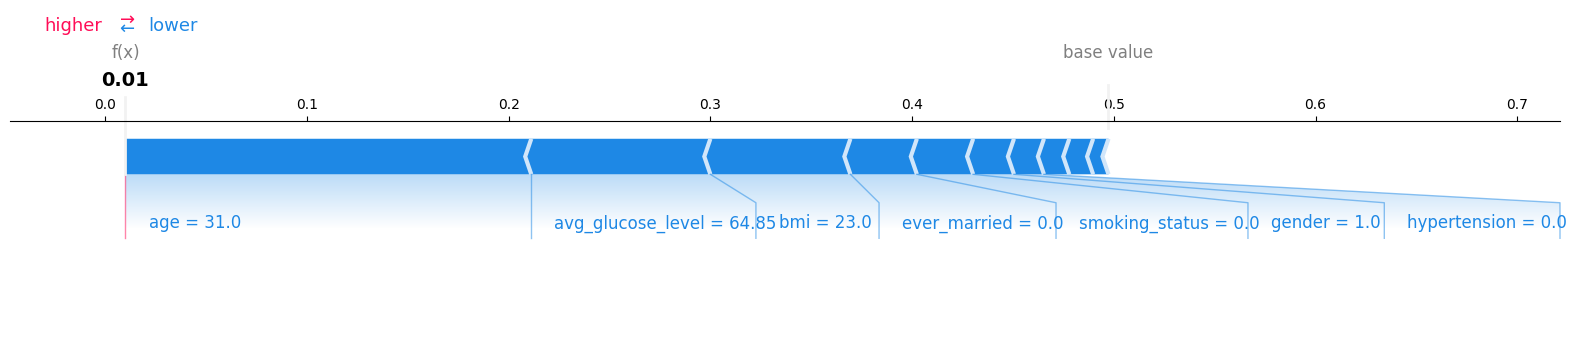

In [7]:
#For Figure 7
# Initialize JS for rendering inside the VS Code notebook viewer
shap.initjs()

# Select Patient index 0 from the test set
patient_index = 0
patient_data = X_test.iloc[patient_index]
actual_outcome = y_test.iloc[patient_index]

print(f"Analyzing Patient {patient_index} | Actual Stroke Outcome: {actual_outcome}")

# Extract SHAP values for this specific patient for Class 1 (Stroke)
if isinstance(shap_values, list):
    # Fallback for older SHAP versions
    patient_shap = shap_values[1][patient_index]
    base_val = explainer.expected_value[1]
else:
    # For newer SHAP versions (3D array)
    patient_shap = shap_values[patient_index, :, 1]
    base_val = explainer.expected_value[1]

# Generate the Force Plot
shap.force_plot(
    base_value=base_val, 
    shap_values=patient_shap, 
    features=patient_data, 
    feature_names=X.columns,
    matplotlib=True
)

C:\Users\sulta\AppData\Local\Temp\ipykernel_40260\4216113591.py:18: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


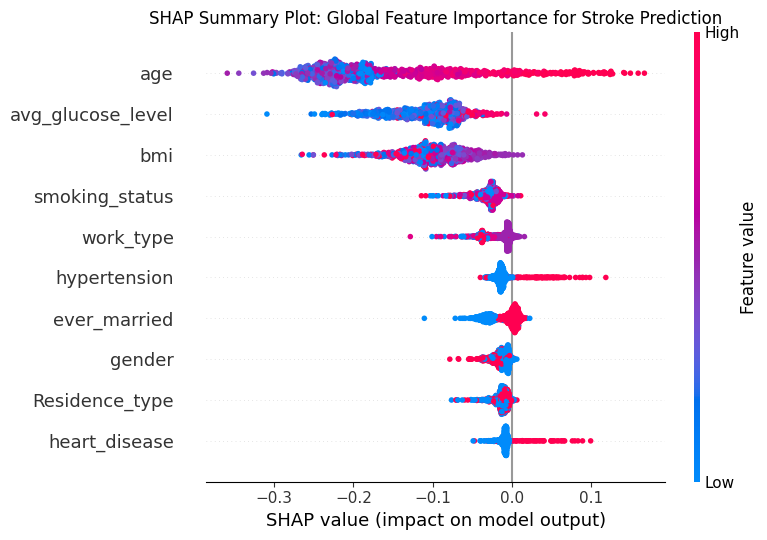

In [8]:
plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot: Global Feature Importance for Stroke Prediction")

# Extract SHAP values for ALL patients for Class 1 (Stroke)
if isinstance(shap_values, list):
    global_shap = shap_values[1]
else:
    global_shap = shap_values[:, :, 1]

# Generate the Summary Plot
shap.summary_plot(
    shap_values=global_shap, 
    features=X_test, 
    feature_names=X.columns,
    show=False
)

plt.tight_layout()
plt.show()

SVM Model trained. Building Kernel Explainer (this may take a minute)...


100%|██████████| 20/20 [14:24<00:00, 43.22s/it]


Kernel SHAP values calculated. Generating plot...


C:\Users\sulta\AppData\Local\Temp\ipykernel_40260\571122025.py:45: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


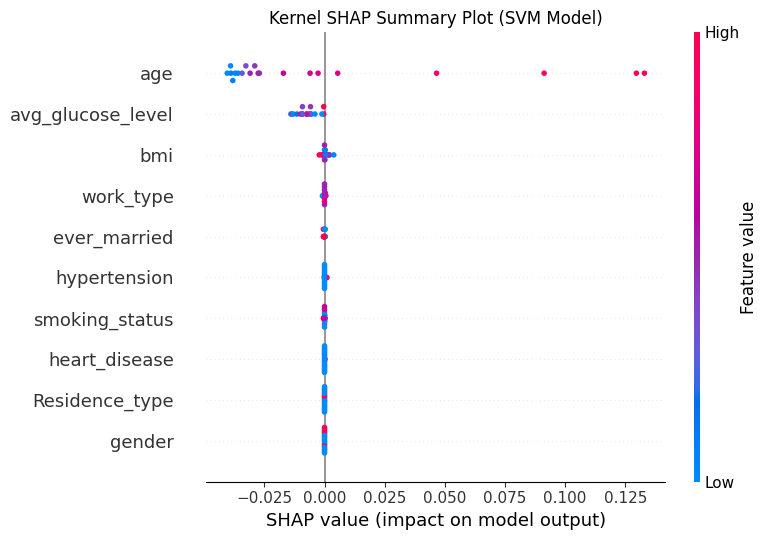

In [10]:
from sklearn.svm import SVC
import shap
import matplotlib.pyplot as plt

# 1. Train SVM Model
svm_model = SVC(probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train, y_train)

print("SVM Model trained. Building Kernel Explainer (this may take a minute)...")

# 2. Summarize background data 
background_data = shap.sample(X_train, 50) 

# 3. Create Kernel SHAP Explainer
kernel_explainer = shap.KernelExplainer(svm_model.predict_proba, background_data)

# 4. Calculate SHAP values for 20 patients
test_sample = X_test.iloc[:20]
kernel_shap_values = kernel_explainer.shap_values(test_sample)

print("Kernel SHAP values calculated. Generating plot...")

# 5. FIX: Correctly slice the SHAP values based on library version
if isinstance(kernel_shap_values, list):
    # Older SHAP versions
    svm_global_shap = kernel_shap_values[1]
elif len(kernel_shap_values.shape) == 3:
    # Newer SHAP versions (3D array: [patients, features, classes])
    svm_global_shap = kernel_shap_values[:, :, 1]
else:
    # Fallback if it returns a 2D array directly
    svm_global_shap = kernel_shap_values

# 6. Visualize the global results
plt.figure(figsize=(10, 6))
plt.title("Kernel SHAP Summary Plot (SVM Model)")

shap.summary_plot(
    shap_values=svm_global_shap, 
    features=test_sample, 
    feature_names=X.columns,
    show=False
)

plt.tight_layout()
plt.show()

In [11]:
#For Table 2
# Get Mean and Standard Deviation for numeric columns
print("--- Numeric Distributions ---")
print(df[['age', 'avg_glucose_level', 'bmi']].describe().loc[['mean', 'std']])

print("\n--- Categorical Distributions ---")
# If you run this BEFORE the LabelEncoder cell, you'll see the text names.
# If you run it AFTER Cell 1, you'll see the integer codes, but the proportions are exactly the same.
print(df['gender'].value_counts(normalize=True) * 100) # Percentages for gender
print(df['work_type'].value_counts(normalize=True) * 100) # Percentages for work type

--- Numeric Distributions ---
            age  avg_glucose_level        bmi
mean  43.226614         106.147677  28.893237
std   22.612647          45.283560   7.698018

--- Categorical Distributions ---
gender
0    58.590998
1    41.389432
2     0.019569
Name: proportion, dtype: float64
work_type
2    57.240705
3    16.027397
4    13.444227
0    12.857143
1     0.430528
Name: proportion, dtype: float64


In [12]:
#For Table 3
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, roc_auc_score, average_precision_score, confusion_matrix

# Get binary predictions and continuous probabilities for the test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate metrics
acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
avg_prec = average_precision_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Print results for the table
print(f"Accuracy: {acc:.4f} | Balanced Accuracy: {bal_acc:.4f}")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))
print("---------------------------")
print(f"ROC AUC: {roc_auc:.4f} | Average Precision: {avg_prec:.4f}")
print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Accuracy: 0.9393 | Balanced Accuracy: 0.5000
--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       960
           1       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

---------------------------
ROC AUC: 0.8095 | Average Precision: 0.2310
Confusion Matrix: TN=960, FP=0, FN=62, TP=0


c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average,

In [13]:
import shap, sklearn; print(shap.__version__, sklearn.__version__)

0.51.0 1.2.2


In [15]:
#For table 4
import numpy as np

# 1. Get the explainer and SHAP values for the test set
# Handle different SHAP version output dimensions
if isinstance(shap_values, list):
    shap_vals_class1 = shap_values[1]
    expected_value = explainer.expected_value[1]
elif len(shap_values.shape) == 3:
    shap_vals_class1 = shap_values[:, :, 1]
    expected_value = explainer.expected_value[1]
else:
    shap_vals_class1 = shap_values
    # Handle array vs scalar expected value
    expected_value = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value

# 2. Select the first patient (Index 0)
patient_idx = 0
patient_shap_sum = np.sum(shap_vals_class1[patient_idx])
reconstructed_output = expected_value + patient_shap_sum

# 3. Get the actual model output for this patient using the ORIGINAL model
actual_model_output = model.predict_proba(X_test.iloc[[patient_idx]])[0][1]

residual = abs(reconstructed_output - actual_model_output)

print(f"Base Value: {expected_value:.4f}")
print(f"Sum of SHAP values: {patient_shap_sum:.4f}")
print(f"Reconstructed Output: {reconstructed_output:.4f}")
print(f"Actual Model Output: {actual_model_output:.4f}")
print(f"Residual: {residual:.4e}")

Base Value: 0.4974
Sum of SHAP values: -0.4874
Reconstructed Output: 0.0100
Actual Model Output: 0.0100
Residual: 1.9771e-14


In [17]:
#For table 5

import pandas as pd

# 1. Combine feature names, actual patient values, and SHAP values
feature_names = X_test.columns
patient_values = X_test.iloc[patient_idx].values
shap_vals = shap_vals_class1[patient_idx]

contributions = pd.DataFrame({
    'Feature': feature_names,
    'Patient Value': patient_values,
    'SHAP Value': shap_vals
})

# 2. Sort by the absolute magnitude of the SHAP value to find the top 3
contributions['Abs_SHAP'] = contributions['SHAP Value'].abs()
contributions = contributions.sort_values(by='Abs_SHAP', ascending=False).reset_index(drop=True)

# 3. Separate top 3 and calculate the remaining sum
top_3 = contributions.head(3)
remaining_sum = contributions.iloc[3:]['SHAP Value'].sum()

# 4. Print results formatted for your table
print("--- TOP 3 FEATURES ---")
for i, row in top_3.iterrows():
    direction = "Increases" if row['SHAP Value'] > 0 else "Decreases"
    print(f"Feature: {row['Feature']} | Value: {row['Patient Value']} | SHAP: {row['SHAP Value']:.4f} | Direction: {direction}")

print("\n--- REMAINING FEATURES COMBINED ---")
rem_direction = "Increases" if remaining_sum > 0 else "Decreases"
print(f"Remaining Sum: {remaining_sum:.4f} | Net Direction: {rem_direction}")

--- TOP 3 FEATURES ---
Feature: age | Value: 31.0 | SHAP: -0.2012 | Direction: Decreases
Feature: avg_glucose_level | Value: 64.85 | SHAP: -0.0888 | Direction: Decreases
Feature: bmi | Value: 23.0 | SHAP: -0.0694 | Direction: Decreases

--- REMAINING FEATURES COMBINED ---
Remaining Sum: -0.1280 | Net Direction: Decreases


In [19]:
#For Table 6

import numpy as np
import pandas as pd

# 1. Calculate the Mean Absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_vals_class1).mean(axis=0)

# 2. Create a DataFrame and sort by importance
global_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean_Abs_SHAP': mean_abs_shap
})
global_importance = global_importance.sort_values(by='Mean_Abs_SHAP', ascending=False).reset_index(drop=True)

# 3. Print the Top 5 features for the table
print("--- TOP 5 FEATURES FOR TABLE 5.2 ---")
for i in range(5):
    row = global_importance.iloc[i]
    print(f"Rank {i+1} | Feature: {row['Feature']} | Mean Abs SHAP: {row['Mean_Abs_SHAP']:.4f}")

--- TOP 5 FEATURES FOR TABLE 5.2 ---
Rank 1 | Feature: age | Mean Abs SHAP: 0.1604
Rank 2 | Feature: avg_glucose_level | Mean Abs SHAP: 0.1077
Rank 3 | Feature: bmi | Mean Abs SHAP: 0.0984
Rank 4 | Feature: smoking_status | Mean Abs SHAP: 0.0310
Rank 5 | Feature: work_type | Mean Abs SHAP: 0.0188


In [21]:
import numpy as np

# 1. Get the base value for class 1 (stroke = 1) from the Kernel Explainer
if isinstance(kernel_explainer.expected_value, (list, np.ndarray)):
    expected_value_svm = kernel_explainer.expected_value[1]
else:
    expected_value_svm = kernel_explainer.expected_value

# 2. Get the SHAP values sum for the first patient in your test_sample
# You already extracted class 1 into 'svm_global_shap' in step 5, making this easy!
patient_shap_sum_svm = np.sum(svm_global_shap[0])

reconstructed_output_svm = expected_value_svm + patient_shap_sum_svm

# 3. Get the actual SVM probability output for this exact same patient
actual_model_output_svm = svm_model.predict_proba(test_sample.iloc[[0]])[0][1]

# 4. Calculate the difference (residual)
residual_svm = abs(reconstructed_output_svm - actual_model_output_svm)

print(f"Base Value: {expected_value_svm:.4f}")
print(f"Sum of SHAP values: {patient_shap_sum_svm:.4f}")
print(f"Reconstructed Output: {reconstructed_output_svm:.4f}")
print(f"Actual Model Output: {actual_model_output_svm:.4f}")
print(f"Kernel SHAP Residual: {residual_svm:.4e}")

Base Value: 0.0485
Sum of SHAP values: -0.0393
Reconstructed Output: 0.0092
Actual Model Output: 0.0092
Kernel SHAP Residual: 1.7347e-18


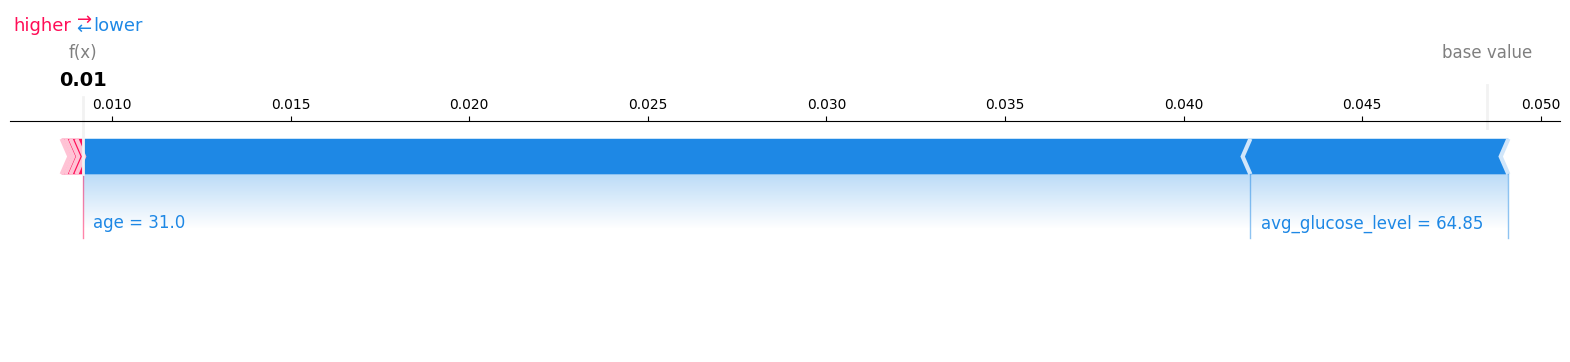

In [22]:
import shap
import matplotlib.pyplot as plt

# Generate the static force plot for the selected patient (Index 0) using SVM Kernel SHAP
shap.force_plot(
    expected_value_svm, 
    svm_global_shap[0], 
    test_sample.iloc[0], 
    matplotlib=True, 
    show=False
)

# Save the plot as a high-res image for the report
plt.savefig('svm_force_plot_patient0.png', bbox_inches='tight', dpi=300)
plt.show()

In [23]:
from sklearn.metrics import classification_report, balanced_accuracy_score, roc_auc_score, average_precision_score

def print_metrics(model_name, y_true, y_pred, y_probs):
    print(f"--- {model_name} METRICS ---")
    report = classification_report(y_true, y_pred, output_dict=True)
    print(f"Positive Class Recall: {report['1']['recall']:.4f}")
    print(f"Positive Class Precision: {report['1']['precision']:.4f}")
    print(f"F1 Score: {report['1']['f1-score']:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
    print(f"ROC AUC: {roc_auc_score(y_true, y_probs):.4f}")
    print(f"Average Precision: {average_precision_score(y_true, y_probs):.4f}")
    print(f"Prevalence: {sum(y_true)/len(y_true):.4f}\n")

# Random Forest Metrics
rf_preds = model.predict(X_test)
rf_probs = model.predict_proba(X_test)[:, 1]
print_metrics("RANDOM FOREST", y_test, rf_preds, rf_probs)

# SVM Metrics
svm_preds = svm_model.predict(X_test)
svm_probs = svm_model.predict_proba(X_test)[:, 1]
print_metrics("SVM", y_test, svm_preds, svm_probs)

--- RANDOM FOREST METRICS ---
Positive Class Recall: 0.0000
Positive Class Precision: 0.0000
F1 Score: 0.0000
Balanced Accuracy: 0.5000
ROC AUC: 0.8095
Average Precision: 0.2310
Prevalence: 0.0607



c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\sulta\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average,

--- SVM METRICS ---
Positive Class Recall: 0.7419
Positive Class Precision: 0.1538
F1 Score: 0.2548
Balanced Accuracy: 0.7392
ROC AUC: 0.8342
Average Precision: 0.1971
Prevalence: 0.0607



In [24]:
#for 8.2.B
# 1. Sample a NEW background dataset (using a different random state)
background_data_2 = shap.sample(X_train, 50, random_state=99) 

# 2. Create a new Kernel Explainer
kernel_explainer_2 = shap.KernelExplainer(svm_model.predict_proba, background_data_2)

# 3. Calculate SHAP values for the same 20 patients
kernel_shap_values_2 = kernel_explainer_2.shap_values(test_sample)

# 4. Extract class 1
if isinstance(kernel_shap_values_2, list):
    svm_global_shap_2 = kernel_shap_values_2[1]
elif len(kernel_shap_values_2.shape) == 3:
    svm_global_shap_2 = kernel_shap_values_2[:, :, 1]
else:
    svm_global_shap_2 = kernel_shap_values_2

# 5. Check if the local prediction for Patient 0 changed
new_base_value = kernel_explainer_2.expected_value[1] if isinstance(kernel_explainer_2.expected_value, (list, np.ndarray)) else kernel_explainer_2.expected_value
new_patient_shap_sum = np.sum(svm_global_shap_2[0])

print(f"--- STABILITY CHECK ---")
print(f"Original Base Value: {expected_value_svm:.4f} | New Base Value: {new_base_value:.4f}")
print(f"Original Patient 0 SHAP Sum: {patient_shap_sum_svm:.4f} | New Patient 0 SHAP Sum: {new_patient_shap_sum:.4f}")

100%|██████████| 20/20 [04:57<00:00, 14.86s/it]

--- STABILITY CHECK ---
Original Base Value: 0.0485 | New Base Value: 0.0470
Original Patient 0 SHAP Sum: -0.0393 | New Patient 0 SHAP Sum: -0.0378
